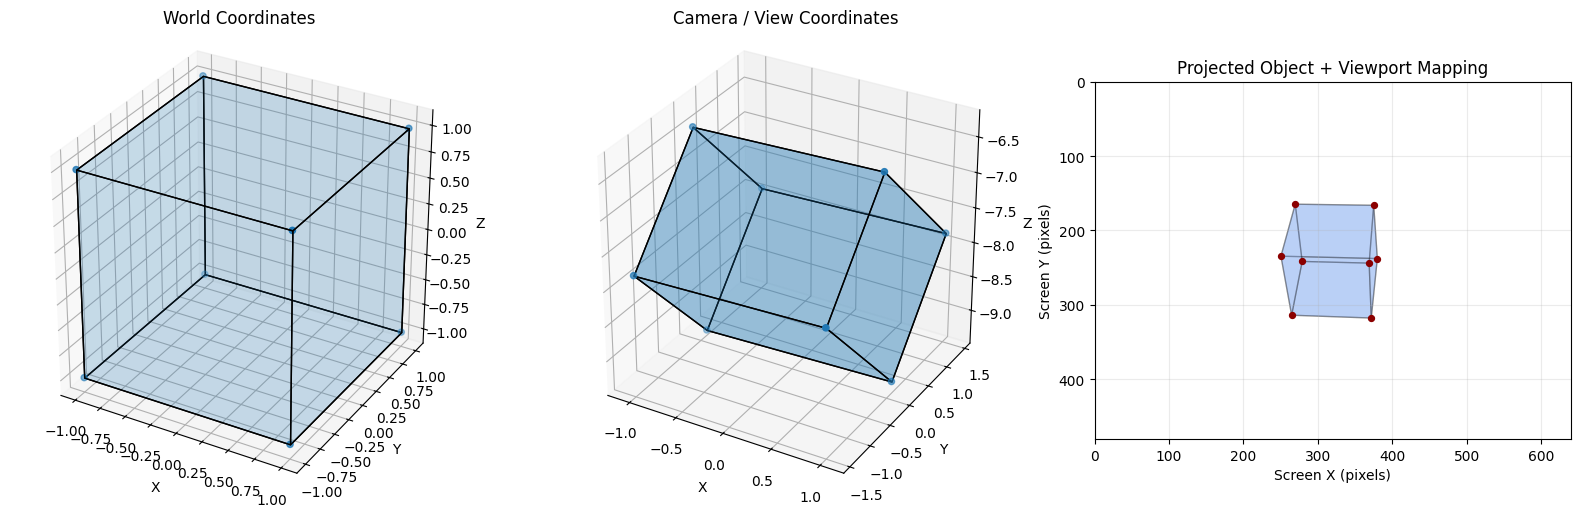

3D viewing pipeline completed.
\nPipeline: Model -> View -> Projection -> Perspective Divide -> Viewport Mapping
Viewport: 640 x 480 pixels
\nExample screen coordinates (first four vertices):
[[278.99 241.6 ]
 [369.02 243.87]
 [375.17 166.13]
 [269.69 164.64]]


In [1]:
# Experiment 10: 3D Viewing Pipeline, Projection, and Viewport Mapping
# Runs in Jupyter Notebook / Google Colab using NumPy and Matplotlib.

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

# ---------- 1. Define a 3D cube in world coordinates ----------
vertices_world = np.array([
    [-1, -1, -1], [ 1, -1, -1], [ 1,  1, -1], [-1,  1, -1],
    [-1, -1,  1], [ 1, -1,  1], [ 1,  1,  1], [-1,  1,  1]
], dtype=float)

faces = [
    [0, 1, 2, 3], [4, 7, 6, 5],
    [0, 4, 5, 1], [3, 2, 6, 7],
    [1, 5, 6, 2], [0, 3, 7, 4]
]

# ---------- 2. Model transformation: rotate and translate ----------
def rotation_y(angle_degrees):
    angle = np.radians(angle_degrees)
    c, s = np.cos(angle), np.sin(angle)
    return np.array([
        [ c, 0, s, 0],
        [ 0, 1, 0, 0],
        [-s, 0, c, 0],
        [ 0, 0, 0, 1]
    ], dtype=float)

def rotation_x(angle_degrees):
    angle = np.radians(angle_degrees)
    c, s = np.cos(angle), np.sin(angle)
    return np.array([
        [1, 0, 0, 0],
        [0, c, -s, 0],
        [0, s, c, 0],
        [0, 0, 0, 1]
    ], dtype=float)

translation = np.array([
    [1, 0, 0, 0.0],
    [0, 1, 0, 0.0],
    [0, 0, 1, 0.0],
    [0, 0, 0, 1.0]
])

model_matrix = translation @ rotation_y(30) @ rotation_x(20)
vertices_h = np.column_stack((vertices_world, np.ones(len(vertices_world))))
vertices_model = (model_matrix @ vertices_h.T).T[:, :3]

# ---------- 3. View transformation: camera looks at origin ----------
def normalize(vector):
    length = np.linalg.norm(vector)
    if length == 0:
        raise ValueError("Cannot normalize a zero-length vector.")
    return vector / length

def look_at(eye, target, up):
    eye = np.array(eye, dtype=float)
    target = np.array(target, dtype=float)
    up = np.array(up, dtype=float)

    forward = normalize(target - eye)
    right = normalize(np.cross(forward, up))
    camera_up = np.cross(right, forward)

    view = np.eye(4)
    view[0, :3] = right
    view[1, :3] = camera_up
    view[2, :3] = -forward
    view[:3, 3] = -view[:3, :3] @ eye
    return view

view_matrix = look_at(
    eye=[4, 3, 6],
    target=[0, 0, 0],
    up=[0, 1, 0]
)
vertices_model_h = np.column_stack((vertices_model, np.ones(len(vertices_model))))
vertices_camera_h = (view_matrix @ vertices_model_h.T).T
vertices_camera = vertices_camera_h[:, :3]

# ---------- 4. Perspective projection ----------
def perspective(fov_degrees, aspect, near, far):
    f = 1.0 / np.tan(np.radians(fov_degrees) / 2.0)
    return np.array([
        [f / aspect, 0, 0, 0],
        [0, f, 0, 0],
        [0, 0, (far + near) / (near - far), (2 * far * near) / (near - far)],
        [0, 0, -1, 0]
    ], dtype=float)

viewport_width, viewport_height = 640, 480
projection_matrix = perspective(
    fov_degrees=60,
    aspect=viewport_width / viewport_height,
    near=0.1,
    far=100.0
)

vertices_clip = (projection_matrix @ vertices_camera_h.T).T
w = vertices_clip[:, 3]
valid = np.abs(w) > 1e-8
vertices_ndc = np.zeros((len(vertices_clip), 3))
vertices_ndc[valid] = vertices_clip[valid, :3] / w[valid, None]

# ---------- 5. Viewport mapping: NDC [-1, 1] to screen coordinates ----------
screen_x = (vertices_ndc[:, 0] + 1) * viewport_width / 2
screen_y = (1 - vertices_ndc[:, 1]) * viewport_height / 2
vertices_screen = np.column_stack((screen_x, screen_y))

# ---------- 6. Visualize pipeline stages ----------
fig = plt.figure(figsize=(16, 5))

ax1 = fig.add_subplot(1, 3, 1, projection="3d")
ax1.scatter(vertices_world[:, 0], vertices_world[:, 1], vertices_world[:, 2])
for face in faces:
    pts = vertices_world[face]
    ax1.add_collection3d(Poly3DCollection([pts], alpha=0.12, edgecolors="black"))
ax1.set_title("World Coordinates")
ax1.set_xlabel("X"); ax1.set_ylabel("Y"); ax1.set_zlabel("Z")
ax1.set_box_aspect((1, 1, 1))

ax2 = fig.add_subplot(1, 3, 2, projection="3d")
for face in faces:
    pts = vertices_camera[face]
    ax2.add_collection3d(Poly3DCollection([pts], alpha=0.25, edgecolors="black"))
ax2.scatter(vertices_camera[:, 0], vertices_camera[:, 1], vertices_camera[:, 2])
ax2.set_title("Camera / View Coordinates")
ax2.set_xlabel("X"); ax2.set_ylabel("Y"); ax2.set_zlabel("Z")
ax2.set_box_aspect((1, 1, 1))

ax3 = fig.add_subplot(1, 3, 3)
for face in faces:
    pts = vertices_screen[face]
    polygon = plt.Polygon(pts, closed=True, facecolor="cornflowerblue",
                          edgecolor="black", alpha=0.25)
    ax3.add_patch(polygon)
ax3.scatter(vertices_screen[:, 0], vertices_screen[:, 1], color="darkred", s=18)
ax3.set_xlim(0, viewport_width)
ax3.set_ylim(viewport_height, 0)
ax3.set_aspect("equal", adjustable="box")
ax3.set_title("Projected Object + Viewport Mapping")
ax3.set_xlabel("Screen X (pixels)")
ax3.set_ylabel("Screen Y (pixels)")
ax3.grid(True, alpha=0.25)

plt.tight_layout()
plt.show()

print("3D viewing pipeline completed.")
print("\\nPipeline: Model -> View -> Projection -> Perspective Divide -> Viewport Mapping")
print(f"Viewport: {viewport_width} x {viewport_height} pixels")
print("\\nExample screen coordinates (first four vertices):")
print(np.round(vertices_screen[:4], 2))
